In [2]:
import pandas as pd

df = pd.read_csv("../data/train.csv", encoding="latin-1")

print(df.shape)
df.head()

(9800, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [5]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.drop(columns="Row ID").duplicated().sum()

np.int64(1)

In [8]:
df[df["Postal Code"].isnull()][["City", "State"]]

,City,State
2234,Burlington,Vermont
5274,Burlington,Vermont
8798,Burlington,Vermont
9146,Burlington,Vermont
9147,Burlington,Vermont
9148,Burlington,Vermont
9386,Burlington,Vermont
9387,Burlington,Vermont
9388,Burlington,Vermont
9389,Burlington,Vermont


# Dataset Understanding

**Dataset:** Superstore Sales Dataset (Kaggle)

## Overview
- The dataset has **9,800 rows and 18 columns**, with each row representing one product line within a customer order.
- It covers order details (Order ID, Order Date, Ship Date, Ship Mode), customer details (Customer ID, Name, Segment), location (Country, City, State, Postal Code, Region), and product details (Product ID, Category, Sub-Category, Product Name), plus **Sales**.

## Key Columns for This Analysis
- **Order Date**: monthly sales trends
- **Sales**: total sales and KPIs
- **Product Name / Category / Sub-Category**: top-selling products
- **Region / State**: regional performance
- **Order ID**: total number of orders

## Data Quality Observations
1. **Missing values:** Only `Postal Code` has missing values (11 out of 9,800 rows). All 11 belong to **Burlington, Vermont**, so the gap comes from one city. All other columns are complete.
2. **Date format:** `Order Date` and `Ship Date` are stored as text (strings) in day/month/year format. They need to be converted to datetime before any time-based analysis.
3. **Duplicates:** A full-row check shows 0 duplicates because every row has a unique `Row ID`. Excluding `Row ID`, **1 duplicate record** was found.
4. **No profit data:** The dataset has no Profit column, so the analysis will focus on sales performance.

## Next Steps (Data Cleaning)
- Inspect and remove the duplicate record
- Fill the 11 missing Postal Code values for Burlington, Vermont
- Convert `Order Date` and `Ship Date` to datetime format

# Day 2: Data Cleaning

In [3]:
df_clean = df.copy()
print(df_clean.shape)

(9800, 18)


In [4]:
cols = [c for c in df_clean.columns if c != "Row ID"]
df_clean[df_clean.duplicated(subset=cols, keep=False)]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
3405,3406,US-2015-150119,23/04/2015,27/04/2015,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229.0,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372
3406,3407,US-2015-150119,23/04/2015,27/04/2015,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229.0,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372


In [5]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=cols, keep="first")
after = len(df_clean)

print("Rows before:", before)
print("Rows after:", after)
print("Duplicates removed:", before - after)

Rows before: 9800
Rows after: 9799
Duplicates removed: 1


In [6]:
df_clean["Postal Code"].isnull().sum()

np.int64(11)

In [7]:
mask = (df_clean["City"] == "Burlington") & (df_clean["State"] == "Vermont") & (df_clean["Postal Code"].isnull())
df_clean.loc[mask, "Postal Code"] = 5401

print("Missing Postal Codes left:", df_clean["Postal Code"].isnull().sum())

Missing Postal Codes left: 0


In [8]:
df_clean["Postal Code"] = df_clean["Postal Code"].astype(int)

In [9]:
df_clean["Order Date"] = pd.to_datetime(df_clean["Order Date"], format="%d/%m/%Y")
df_clean["Ship Date"] = pd.to_datetime(df_clean["Ship Date"], format="%d/%m/%Y")

df_clean[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [10]:
print(df_clean["Order Date"].min(), "to", df_clean["Order Date"].max())

2015-01-03 00:00:00 to 2018-12-30 00:00:00


In [11]:
(df_clean["Ship Date"] < df_clean["Order Date"]).sum()

np.int64(0)

In [12]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 9799 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9799 non-null   int64         
 1   Order ID       9799 non-null   str           
 2   Order Date     9799 non-null   datetime64[us]
 3   Ship Date      9799 non-null   datetime64[us]
 4   Ship Mode      9799 non-null   str           
 5   Customer ID    9799 non-null   str           
 6   Customer Name  9799 non-null   str           
 7   Segment        9799 non-null   str           
 8   Country        9799 non-null   str           
 9   City           9799 non-null   str           
 10  State          9799 non-null   str           
 11  Postal Code    9799 non-null   int64         
 12  Region         9799 non-null   str           
 13  Product ID     9799 non-null   str           
 14  Category       9799 non-null   str           
 15  Sub-Category   9799 non-null   str   

In [13]:
df_clean.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
dtype: int64

In [14]:
df_clean.drop(columns="Row ID").duplicated().sum()

np.int64(0)

In [15]:
(df_clean["Ship Date"] < df_clean["Order Date"]).sum()

np.int64(0)

In [16]:
print(df_clean["Order Date"].min(), "to", df_clean["Order Date"].max())

2015-01-03 00:00:00 to 2018-12-30 00:00:00


In [17]:
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Missing values (original):", df.isnull().sum().sum())
print("Missing values (cleaned):", df_clean.isnull().sum().sum())

Original rows: 9800
Cleaned rows: 9799
Missing values (original): 11
Missing values (cleaned): 0


In [18]:
df_clean.to_csv("../data/cleaned_train.csv", index=False)

## Data Cleaning Summary

| Issue | Action Taken | Result |
|---|---|---|
| 1 duplicate record (ignoring Row ID): Order US-2015-150119, Global Leather Highback Executive Chair (Row IDs 3406 and 3407) | Inspected both rows, kept the first and removed the second using `drop_duplicates` | 9,800 → 9,799 rows |
| 11 missing Postal Codes (all Burlington, Vermont) | Filled with 5401 (05401) and converted the column to integer | 0 missing values |
| Order Date and Ship Date stored as text | Converted to datetime using the `%d/%m/%Y` format | Both columns are now datetime64 |

## Verification
- **Rows:** 9,800 (original) → 9,799 (cleaned)
- **Missing values:** 11 (original) → 0 (cleaned)
- **Duplicates (excluding Row ID):** 1 → 0
- **Date check:** 0 orders shipped before their order date
- **Date range of the data:** 3 January 2015 to 30 December 2018

**Cleaned dataset saved as:** `data/cleaned_train.csv`

## Next Steps (Day 3)
- Calculate total sales and total number of orders
- Analyze the monthly sales trend

# Day 3: KPIs and Monthly Sales Trend

In [19]:
import pandas as pd

df = pd.read_csv("../data/cleaned_train.csv", parse_dates=["Order Date", "Ship Date"])

print(df.shape)
df.dtypes[["Order Date", "Ship Date"]]

(9799, 18)


Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [20]:
total_sales = df["Sales"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
avg_order_value = total_sales / total_orders

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Order Value: ${avg_order_value:,.2f}")

Total Sales: $2,261,255.41
Total Orders: 4,922
Total Customers: 793
Average Order Value: $459.42


In [21]:
df["Month"] = df["Order Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Sales"].sum().reset_index()
monthly_sales["Sales"] = monthly_sales["Sales"].round(2)

print(monthly_sales.shape)
monthly_sales

(48, 2)


,Month,Sales
0,2015-01,14205.71
1,2015-02,4519.89
2,2015-03,55205.80
3,2015-04,27625.48
4,2015-05,23644.30
5,2015-06,34322.94
6,2015-07,33781.54
7,2015-08,27117.54
8,2015-09,81623.53
9,2015-10,31453.39


In [22]:
best = monthly_sales.loc[monthly_sales["Sales"].idxmax()]
worst = monthly_sales.loc[monthly_sales["Sales"].idxmin()]

print("Best month:", best["Month"], "->", best["Sales"])
print("Worst month:", worst["Month"], "->", worst["Sales"])

Best month: 2018-11 -> 117938.16
Worst month: 2015-02 -> 4519.89


In [23]:
df["Year"] = df["Order Date"].dt.year

yearly_sales = df.groupby("Year")["Sales"].sum().round(2).reset_index()
yearly_sales["Growth %"] = (yearly_sales["Sales"].pct_change() * 100).round(1)

yearly_sales

,Year,Sales,Growth %
0,2015,479574.84,NaN
1,2016,459436.01,-4.2
2,2017,600192.55,30.6
3,2018,722052.02,20.3


In [24]:
df["Month Number"] = df["Order Date"].dt.month

seasonal = df.groupby("Month Number")["Sales"].sum().round(2).reset_index()
seasonal.sort_values("Sales", ascending=False)

,Month Number,Sales
10,11,350161.71
11,12,321480.17
8,9,300103.41
9,10,199496.29
2,3,197573.59
7,8,157315.93
4,5,154086.72
5,6,145837.52
6,7,145535.69
3,4,136001.63


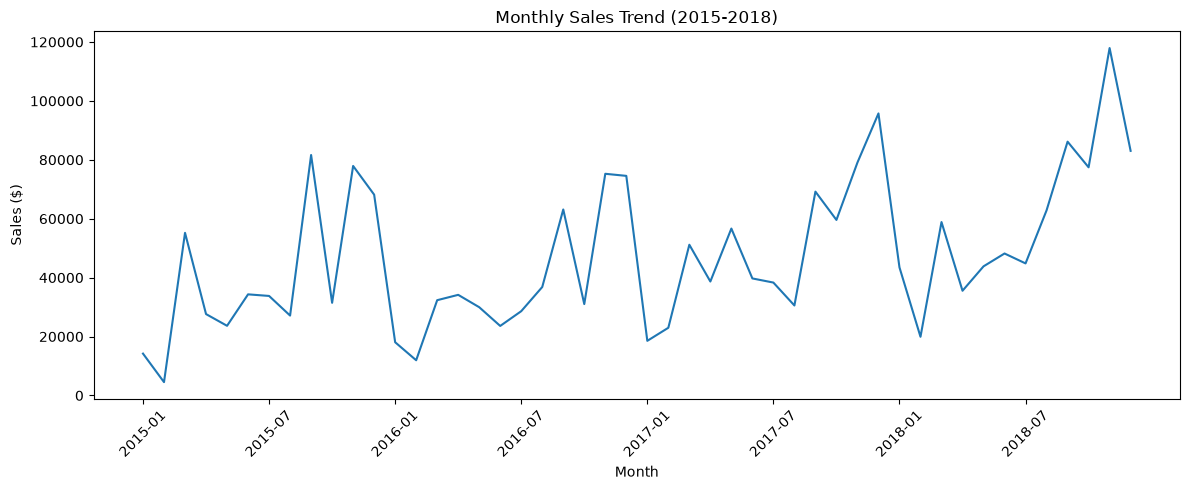

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Month"].astype(str), monthly_sales["Sales"])
plt.xticks(range(0, len(monthly_sales), 6), rotation=45)
plt.title("Monthly Sales Trend (2015-2018)")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

## Day 3 Observations

**Headline KPIs**
- Total Sales: $2,261,255.41
- Total Orders: 4,922
- Total Customers: 793
- Average Order Value: $459.42

**Monthly trend**
- Best month: November 2018 ($117,938.16)
- Worst month: February 2015 ($4,519.89)
- Sales grew from 2015 to 2018, with yearly totals of 2015: $479,574.84, 2016: $459,436.01, 2017: $600,192.55, 2018: $722,052.02.
- The strongest calendar months across all years are November, December and September, which suggests a seasonal pattern with peak demand in the last quarter of the year.

In [26]:
print(df.shape)

(9799, 21)


In [27]:
top_products = (df.groupby("Product Name")["Sales"].sum()
                  .sort_values(ascending=False)
                  .head(10).round(2).reset_index())
top_products

,Product Name,Sales
0,Canon imageCLASS 2200 Advanced Copier,61599.82
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38
2,Cisco TelePresence System EX90 Videoconferenci...,22638.48
3,HON 5400 Series Task Chairs for Big and Tall,21870.58
4,GBC DocuBind TL300 Electric Binding System,19823.48
5,GBC Ibimaster 500 Manual ProClick Binding System,19024.50
6,Hewlett Packard LaserJet 3310 Copier,18839.69
7,HP Designjet T520 Inkjet Large Format Printer ...,18374.90
8,GBC DocuBind P400 Electric Binding System,17965.07
9,High Speed Automatic Electric Letter Opener,17030.31


In [28]:
bottom_products = (df.groupby("Product Name")["Sales"].sum()
                     .sort_values()
                     .head(5).round(2).reset_index())
bottom_products

,Product Name,Sales
0,Eureka Disposable Bags for Sanitaire Vibra Gro...,1.62
1,Avery 5,5.76
2,Xerox 20,6.48
3,Grip Seal Envelopes,7.07
4,Acme Serrated Blade Letter Opener,7.63


In [29]:
top10_share = top_products["Sales"].sum() / df["Sales"].sum() * 100
print(f"Top 10 products contribute {top10_share:.1f}% of total sales")

Top 10 products contribute 10.8% of total sales


In [30]:
category_sales = df.groupby("Category")["Sales"].sum().round(2).reset_index()
category_sales["Share %"] = (category_sales["Sales"] / category_sales["Sales"].sum() * 100).round(1)
category_sales.sort_values("Sales", ascending=False)

,Category,Sales,Share %
2,Technology,827455.87,36.6
0,Furniture,728377.20,32.2
1,Office Supplies,705422.33,31.2


In [31]:
subcat_sales = df.groupby("Sub-Category")["Sales"].sum().round(2).reset_index()
subcat_sales["Share %"] = (subcat_sales["Sales"] / subcat_sales["Sales"].sum() * 100).round(1)
subcat_sales.sort_values("Sales", ascending=False)

,Sub-Category,Sales,Share %
13,Phones,327782.45,14.5
5,Chairs,322541.36,14.3
14,Storage,219343.39,9.7
16,Tables,202810.63,9.0
3,Binders,200028.78,8.8
11,Machines,189238.63,8.4
0,Accessories,164186.70,7.3
6,Copiers,146248.09,6.5
4,Bookcases,113813.20,5.0
1,Appliances,104618.40,4.6


In [32]:
region_sales = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Orders=("Order ID", "nunique")
).round(2).reset_index()
region_sales["Share %"] = (region_sales["Sales"] / region_sales["Sales"].sum() * 100).round(1)
region_sales["Avg Order Value"] = (region_sales["Sales"] / region_sales["Orders"]).round(2)
region_sales.sort_values("Sales", ascending=False)

,Region,Sales,Orders,Share %,Avg Order Value
3,West,710219.68,1587,31.4,447.52
1,East,669237.35,1369,29.6,488.85
0,Central,492646.91,1156,21.8,426.17
2,South,389151.46,810,17.2,480.43


In [33]:
state_sales = df.groupby("State")["Sales"].sum().round(2).sort_values(ascending=False)
state_sales.head(10)

State
California      446306.46
New York        306361.15
Texas           168572.53
Washington      135206.85
Pennsylvania    116276.65
Florida          88436.53
Illinois         79236.52
Michigan         76136.07
Ohio             74848.98
Virginia         70636.72
Name: Sales, dtype: float64

In [34]:
state_sales.tail(5)

State
Wyoming          1603.14
South Dakota     1315.56
Maine            1270.53
West Virginia    1209.82
North Dakota      919.91
Name: Sales, dtype: float64

In [35]:
region_category = df.pivot_table(index="Region", columns="Category",
                                 values="Sales", aggfunc="sum").round(2)
region_category

Category,Furniture,Office Supplies,Technology
Region,,,
Central,160317.46,163590.24,168739.21
East,206180.02,199940.81,263116.53
South,116531.48,124424.77,148195.21
West,245348.25,217466.51,247404.93


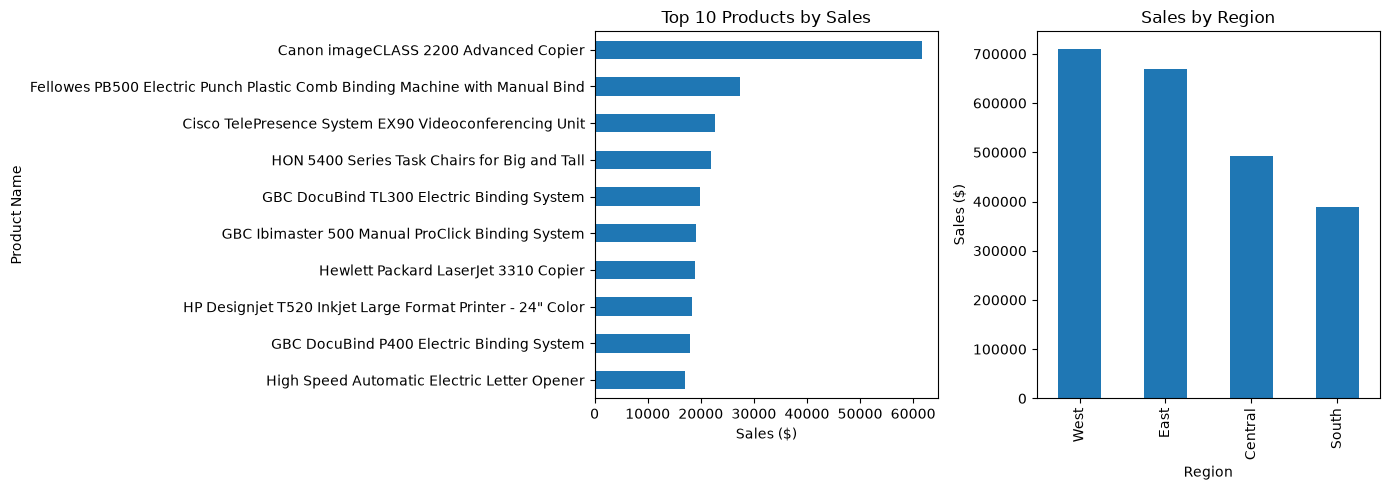

In [36]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_products.sort_values("Sales").plot.barh(x="Product Name", y="Sales", ax=axes[0], legend=False)
axes[0].set_title("Top 10 Products by Sales")
axes[0].set_xlabel("Sales ($)")

region_sales.sort_values("Sales", ascending=False).plot.bar(x="Region", y="Sales", ax=axes[1], legend=False)
axes[1].set_title("Sales by Region")
axes[1].set_ylabel("Sales ($)")

plt.tight_layout()
plt.show()

## Day 4 Observations

**Products**
- Top 3 products: Canon imageCLASS 2200 Advanced Copier ($61,599.82), Fellowes PB500 Electric Punch Plastic Comb Binding Machine ($27,453.38), Cisco TelePresence System EX90 ($22,638.48).
- The top 10 products contribute only 10.8% of total sales, so sales are spread across many products.

**Category and Sub-Category**
- Top category: Technology ($827,455.87, 36.6%). Lowest: Office Supplies ($705,422.33, 31.2%).
- Top sub-categories: Phones (14.5%), Chairs (14.3%), Storage (9.7%). Weakest: Fasteners (0.1%), Labels (0.5%), Envelopes (0.7%).

**Regions and States**
- Best region: West ($710,219.68, 31.4%). Weakest: South ($389,151.46, 17.2%).
- Top 3 states: California ($446,306.46), New York ($306,361.15), Texas ($168,572.53).
- Technology is the top category in every region.

# Day 5: Business Insights and Notebook Review

In [37]:
total = df["Sales"].sum()

q4 = df[df["Order Date"].dt.month.isin([10, 11, 12])]["Sales"].sum()
print(f"Q4 (Oct-Dec) share of sales: {q4 / total * 100:.1f}%")

west_east = df[df["Region"].isin(["West", "East"])]["Sales"].sum()
print(f"West + East share: {west_east / total * 100:.1f}%")

ca_ny = df[df["State"].isin(["California", "New York"])]["Sales"].sum()
print(f"California + New York share: {ca_ny / total * 100:.1f}%")

phones_chairs = df[df["Sub-Category"].isin(["Phones", "Chairs"])]["Sales"].sum()
print(f"Phones + Chairs share: {phones_chairs / total * 100:.1f}%")

jan_feb = df[df["Order Date"].dt.month.isin([1, 2])]["Sales"].sum()
print(f"January + February share: {jan_feb / total * 100:.1f}%")

Q4 (Oct-Dec) share of sales: 38.5%
West + East share: 61.0%
California + New York share: 33.3%
Phones + Chairs share: 28.8%
January + February share: 6.8%


## Business Insights

**1. Sales are strongly seasonal, peaking in Q4.**
November, December and September are the strongest months. October to December alone bring about 38.5% of all sales, while January and February are the weakest months in every year (February 2015 was the lowest at $4,519.89, November 2018 the highest at $117,938.16).
*Recommendation:* build inventory and run promotions ahead of Q4, and use targeted offers to lift the slow January to February period.

**2. Sales are growing, with a strong recovery after 2016.**
Yearly sales went from $479,574.84 (2015) to $459,436.01 (2016, -4.2%), then $600,192.55 (2017, +30.6%) and $722,052.02 (2018, +20.3%).
*Recommendation:* identify what drove the 2017 and 2018 growth and repeat it.

**3. Technology is the top category, and it leads in every region.**
Technology brings 36.6% of sales ($827,455.87), ahead of Furniture (32.2%) and Office Supplies (31.2%). Phones (14.5%) and Chairs (14.3%) are the top sub-categories and together bring about 28.8% of sales.
*Recommendation:* protect stock and availability of phones and chairs, since they carry the largest share of sales.

**4. Sales are concentrated in the West and East regions and in two states.**
The West ($710,219.68) and East ($669,237.35) together bring about 61.0% of sales, and California and New York alone bring about 33.3%. The South is the smallest region (17.2%, 810 orders).
*Recommendation:* protect the core markets of California and New York, and run growth campaigns in the South and Central regions.

**5. Order value differs by region.**
The East has the highest average order value ($488.85) and the Central region the lowest ($426.17). The West leads on order volume (1,587 orders) but has a below-average order size ($447.52).
*Recommendation:* use bundles and upsell offers in the West and Central regions to raise order size.

**6. Sales are spread across many products, and some sub-categories add little.**
The top 10 products contribute only 10.8% of sales. Fasteners (0.1%), Labels (0.5%) and Envelopes (0.7%) each contribute under 1%.
*Recommendation:* review whether the lowest sub-categories deserve the shelf space and marketing effort they currently get.

**Limitation:** the dataset has no Profit column, so these insights are based on sales, not profitability.

In [38]:
monthly_sales.assign(Month=monthly_sales["Month"].astype(str)).to_csv("../data/monthly_sales.csv", index=False)
yearly_sales.to_csv("../data/yearly_sales.csv", index=False)
category_sales.to_csv("../data/category_sales.csv", index=False)
subcat_sales.to_csv("../data/subcategory_sales.csv", index=False)
region_sales.to_csv("../data/region_sales.csv", index=False)
top_products.to_csv("../data/top_products.csv", index=False)
state_sales.reset_index().to_csv("../data/state_sales.csv", index=False)

print("Summary tables saved")

Summary tables saved


## Week 1 Summary
- Cleaned the Superstore dataset (9,800 → 9,799 rows, 0 missing values, dates converted).
- Total sales of $2.26M across 4,922 orders and 793 customers, growing from $479.6K (2015) to $722.1K (2018).
- Key drivers: a Q4 seasonal peak, Technology as the top category, and strong concentration in the West and East regions.
- Next: final charts and the dashboard in Week 2.

In [40]:
import os
import calendar
import matplotlib.pyplot as plt

os.makedirs("../reports/charts", exist_ok=True)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

k_fmt = lambda x, _: f"${x/1000:,.0f}K"

def finish(fig, ax, title, xlabel, ylabel, filename):
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    fig.tight_layout()
    fig.savefig(f"../reports/charts/{filename}", dpi=150)
    plt.show()

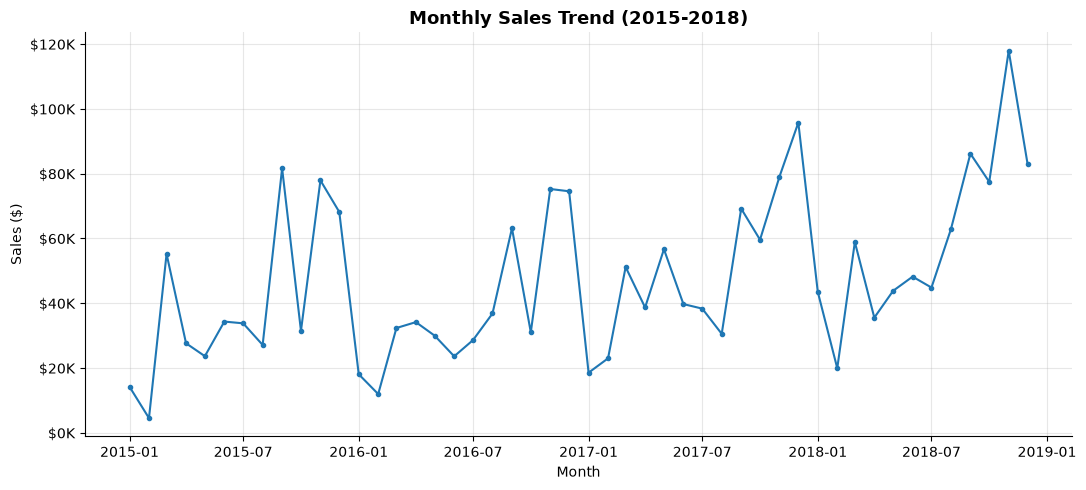

In [41]:
m = monthly_sales.copy()
m["Month"] = m["Month"].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(m["Month"], m["Sales"], marker="o", markersize=3, linewidth=1.5)
ax.yaxis.set_major_formatter(k_fmt)
finish(fig, ax, "Monthly Sales Trend (2015-2018)", "Month", "Sales ($)", "01_monthly_sales_trend.png")

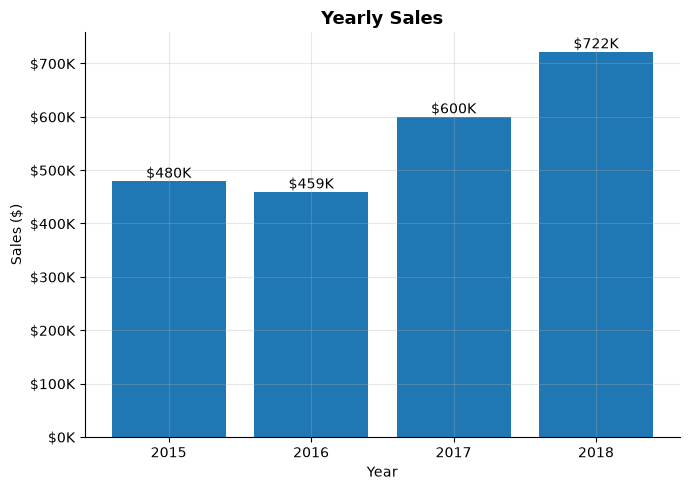

In [42]:
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(yearly_sales["Year"].astype(str), yearly_sales["Sales"])
ax.bar_label(bars, labels=[f"${v/1000:,.0f}K" for v in yearly_sales["Sales"]])
ax.yaxis.set_major_formatter(k_fmt)
finish(fig, ax, "Yearly Sales", "Year", "Sales ($)", "02_yearly_sales.png")

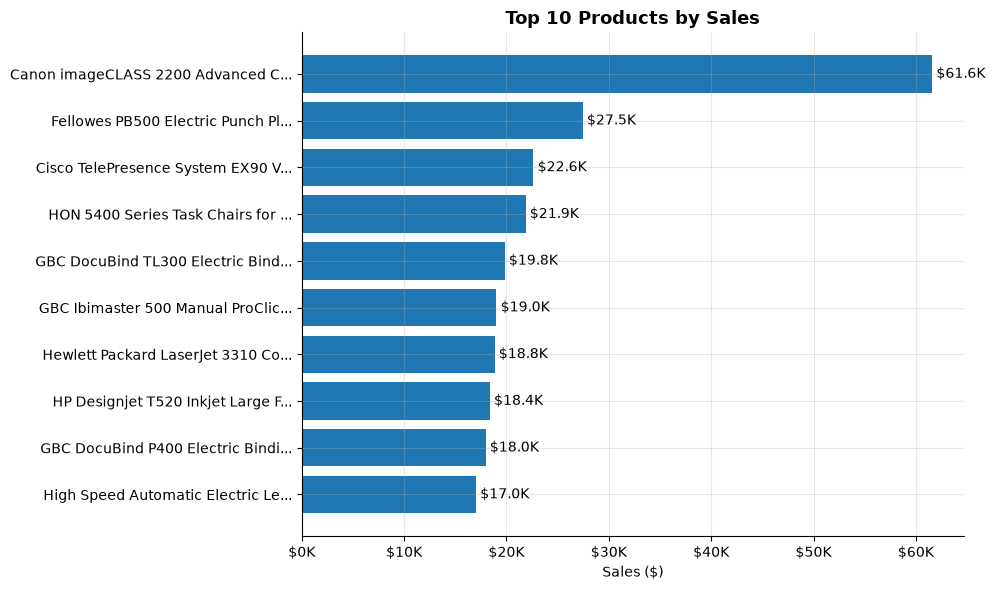

In [43]:
t = top_products.sort_values("Sales").copy()
t["Short"] = t["Product Name"].apply(lambda s: s if len(s) <= 32 else s[:32] + "...")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(t["Short"], t["Sales"])
ax.bar_label(bars, labels=[f"${v/1000:,.1f}K" for v in t["Sales"]], padding=3)
ax.xaxis.set_major_formatter(k_fmt)
finish(fig, ax, "Top 10 Products by Sales", "Sales ($)", "", "03_top_products.png")

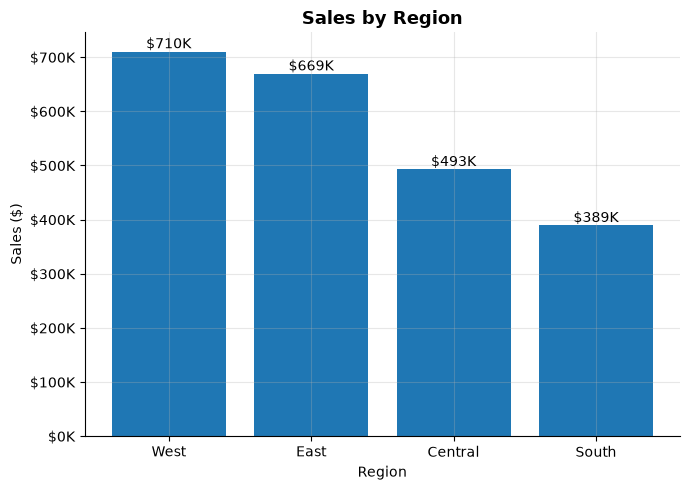

In [44]:
r = region_sales.sort_values("Sales", ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(r["Region"], r["Sales"])
ax.bar_label(bars, labels=[f"${v/1000:,.0f}K" for v in r["Sales"]])
ax.yaxis.set_major_formatter(k_fmt)
finish(fig, ax, "Sales by Region", "Region", "Sales ($)", "04_sales_by_region.png")

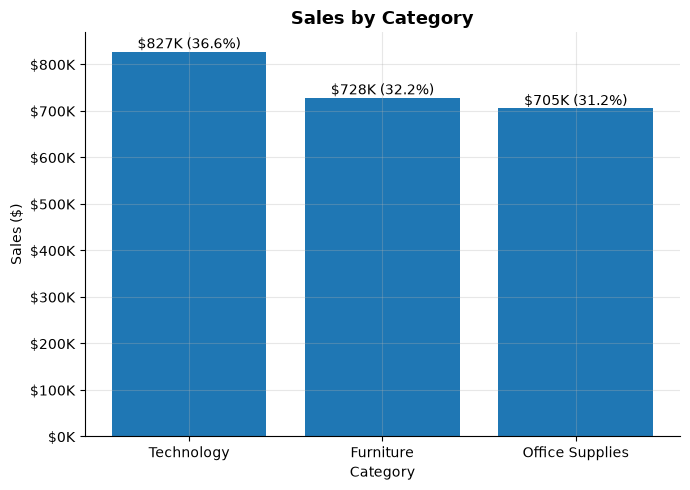

In [45]:
c = category_sales.sort_values("Sales", ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(c["Category"], c["Sales"])
ax.bar_label(bars, labels=[f"${s/1000:,.0f}K ({p}%)" for s, p in zip(c["Sales"], c["Share %"])])
ax.yaxis.set_major_formatter(k_fmt)
finish(fig, ax, "Sales by Category", "Category", "Sales ($)", "05_sales_by_category.png")

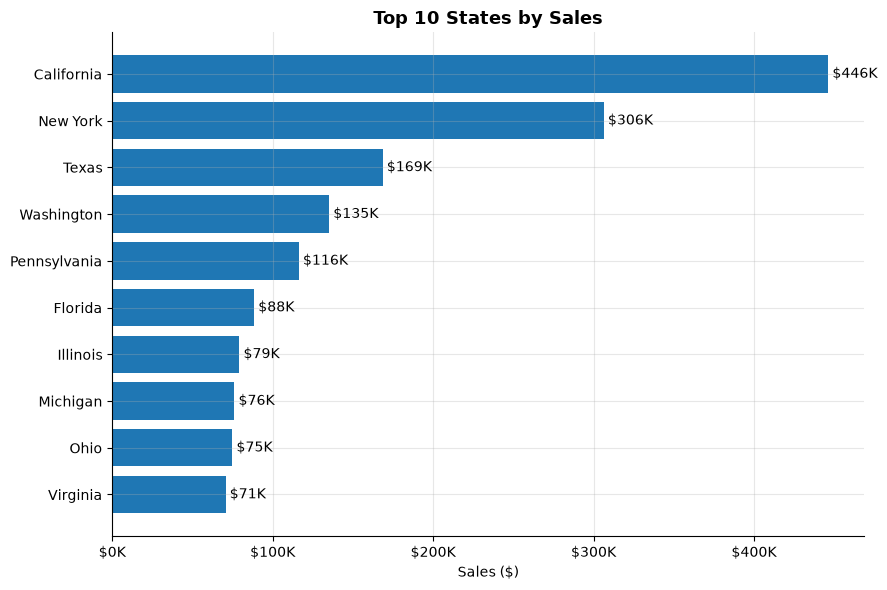

In [46]:
s = state_sales.head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(s.index, s.values)
ax.bar_label(bars, labels=[f"${v/1000:,.0f}K" for v in s.values], padding=3)
ax.xaxis.set_major_formatter(k_fmt)
finish(fig, ax, "Top 10 States by Sales", "Sales ($)", "", "06_top_states.png")

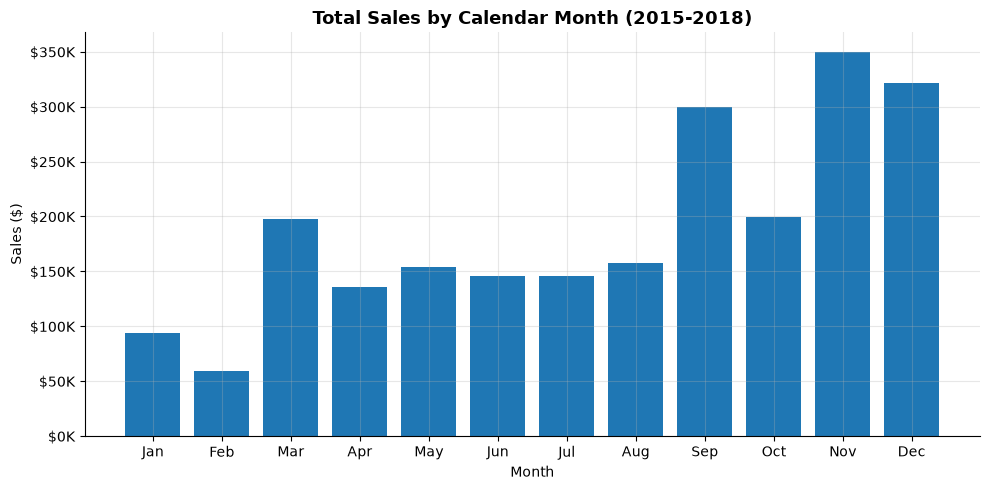

In [47]:
se = seasonal.copy()
se["Month"] = se["Month Number"].apply(lambda n: calendar.month_abbr[n])

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(se["Month"], se["Sales"])
ax.yaxis.set_major_formatter(k_fmt)
finish(fig, ax, "Total Sales by Calendar Month (2015-2018)", "Month", "Sales ($)", "07_seasonality.png")